# 1. Selección y alcance del dataset

## 1.1 Descripción del dataset elegido

**Nombre del dataset:** Microdatos de la Encuesta Permanente de Hogares (EPH), primer trimestre de 2026.

**Fuente:** Instituto Nacional de Estadística y Censos (INDEC), organismo oficial de estadísticas de la República Argentina.

**Formato:** .xlsx

**Link:** https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/EPH_usu_1_Trim_2026_txt.zip

**Diccionario del dataset**:

- 0 `NIVEL_ED`: identifica el máximo nivel educativo alcanzado por la persona.
- 1`ESTADO`: indica la situación laboral de la persona, como ocupada, desocupada o inactiva.
- 2 `EMPLEO`: indica la clasificación del empleo según la definición de la EPH, incluyendo formalidad e informalidad, según el universo al que se aplica.
- 3 `P21`: monto de ingreso de la ocupación principal, expresado en pesos argentinos.
- 4 `P47T`: monto del ingreso total individual, que comprende ingresos laborales y no laborales, expresado en pesos argentinos.
- 5 `T_VI`: monto total de ingresos no laborales, expresado en pesos argentinos.
- 6 `PONDERA`: factor de expansión utilizado para estimar la población representada por cada registro de la encuesta.
- 7 `REGION`: identifica la región estadística a la que pertenece el aglomerado urbano.
- 8 `CODUSU`: identifica la vivienda.
- 9 `NRO_HOGAR`	identifica el hogar dentro de la vivienda.
- 10`COMPONENTE`: identifica a la persona dentro del hogar.


## 1.2 Objetivo general del proyecto
Analizar la relación entre el nivel educativo alcanzado y la situación laboral y económica de las personas en la región del Noreste Argentino (NEA), durante el primer trimestre de 2026, utilizando microdatos de la Encuesta Permanente de Hogares (EPH) del INDEC, con énfasis en el desempleo, la informalidad laboral y las diferencias de ingresos.


## 1.3 Preguntas de investigación

**Pregunta 1. Educación y desempleo**

¿Cómo varía la proporción de personas desocupadas según el nivel educativo alcanzado?

**Pregunta 2. Educación e informalidad laboral**

¿Qué proporción de las personas ocupadas se encuentra en empleos informales según su nivel educativo?

**Pregunta 3. Educación e ingresos**

¿Qué diferencias existen en los ingresos laborales y totales individuales según el nivel educativo alcanzado?

##1.4 Validación de viabilidad

| Pregunta de investigación | Columnas necesarias | ¿Están en el dataset? | ¿Viable? |
|---|---|---|---|
| **P1**| `NIVEL_ED`, `ESTADO`, `PONDERA` | Si| Si |
| **P2** | `NIVEL_ED`, `ESTADO`, `EMPLEO`, `PONDERA` | Si | Si |
| **P3** | `NIVEL_ED`, `P21`, `P47T`, `PONDERA` | Si | Si |


# 2. Carga del dataset

In [ ]:
# Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA_ARCHIVO = "/content/drive/MyDrive/Colab Notebooks/usu_individual_T126.xlsx"

In [ ]:
df = pd.read_excel(RUTA_ARCHIVO)

In [ ]:
# Filtrar la región NEA
df = df[df["REGION"] == 41].copy()

# Identificadores individuales de la EPH
identificadores = [
    "CODUSU",
    "NRO_HOGAR",
    "COMPONENTE"
]

# Variables necesarias para el análisis
columnas = [
    "NIVEL_ED",
    "ESTADO",
    "EMPLEO",
    "P21",
    "P47T",
    "T_VI",
    "PONDERA",
    "REGION"
]

# Conservar identificadores y variables de análisis
df = df[identificadores + columnas].copy()

# Preparación de los datos

## Diagnóstico

In [ ]:
print("Dimensiones:", df.shape)

Dimensiones: (4589, 11)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4589 entries, 34 to 43691
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CODUSU      4589 non-null   object 
 1   NRO_HOGAR   4589 non-null   int64  
 2   COMPONENTE  4589 non-null   int64  
 3   NIVEL_ED    4589 non-null   int64  
 4   ESTADO      4589 non-null   int64  
 5   EMPLEO      1949 non-null   float64
 6   P21         4589 non-null   int64  
 7   P47T        4585 non-null   float64
 8   T_VI        4589 non-null   int64  
 9   PONDERA     4589 non-null   int64  
 10  REGION      4589 non-null   int64  
dtypes: float64(2), int64(8), object(1)
memory usage: 430.2+ KB


De la primera lectura del dataset, se observa que las columnas presentan tipos de datos adecuados para su análisis. Sin embargo, la variable `EMPLEO` contiene valores nulos, por lo que será necesario evaluar la cantidad de datos faltantes y determinar cómo tratarlos antes de realizar el análisis de la informalidad laboral.

In [ ]:
#Inspección de datos nulos
df.isna().sum()

,0
CODUSU,0
NRO_HOGAR,0
COMPONENTE,0
NIVEL_ED,0
ESTADO,0
EMPLEO,2640
P21,0
P47T,4
T_VI,0
PONDERA,0


In [ ]:
#Porcentaje de valores nulos por columna
df.isnull().sum()
(df.isnull().mean() * 100).round(2)

,0
CODUSU,0.00
NRO_HOGAR,0.00
COMPONENTE,0.00
NIVEL_ED,0.00
ESTADO,0.00
EMPLEO,57.53
P21,0.00
P47T,0.09
T_VI,0.00
PONDERA,0.00


In [ ]:
# Inconsistencias
# Filas duplicadas completas
print("Filas duplicadas:", df.duplicated().sum())


Filas duplicadas: 0


In [ ]:
# Verificar registros duplicados mediante los identificadores

print("Cantidad de registros:", len(df))

print(
    "Registros con identificadores duplicados:",
    df.duplicated(
        subset=["CODUSU", "NRO_HOGAR", "COMPONENTE"]
    ).sum()
)

print(
    "Cantidad de personas identificadas:",
    df.drop_duplicates(
        subset=["CODUSU", "NRO_HOGAR", "COMPONENTE"]
    ).shape[0]
)

Cantidad de registros: 4589
Registros con identificadores duplicados: 0
Cantidad de personas identificadas: 4589


In [ ]:
# Revisar identificadores nulos

df[["CODUSU", "NRO_HOGAR", "COMPONENTE"]].isnull().sum()

,0
CODUSU,0
NRO_HOGAR,0
COMPONENTE,0


**Verificación de registros duplicados**

Se realizaron dos comprobaciones para evaluar la existencia de registros repetidos en el conjunto de datos.

En primer lugar, se verificó la presencia de filas completamente idénticas considerando todas las columnas seleccionadas. Posteriormente, se comprobó la unicidad de las personas mediante la combinación de los identificadores `CODUSU`, `NRO_HOGAR` y `COMPONENTE`.

En ambos controles se obtuvo un resultado de cero duplicados. Por lo tanto, se conservaron las 4.589 observaciones originales, manteniendo los identificadores individuales para garantizar la trazabilidad de los registros durante el análisis.

In [ ]:
columnas_num = ["P21", "P47T", "T_VI", "PONDERA"]
df[columnas_num].describe().T

,count,mean,std,min,25%,50%,75%,max
P21,4589.0,229430.617564,679155.033694,-9.0,0.0,0.0,300000.0,30000000.0
P47T,4585.0,375934.521047,766833.808648,-9.0,0.0,0.0,580000.0,30000000.0
T_VI,4589.0,121594.936152,291647.291290,-9.0,0.0,0.0,0.0,4000000.0
PONDERA,4589.0,324.369362,137.545079,49.0,230.0,312.0,385.0,1021.0


Inspección de datos nulos en la columna EMPLEO

In [ ]:
#Comprobar si los nulos se concentran en personas no ocupadas
pd.crosstab(
    df["ESTADO"],
    df["EMPLEO"].isna(),
    margins=True
)

EMPLEO,False,True,All
ESTADO,,,
0,0,4,4
1,1949,0,1949
2,0,155,155
3,0,1951,1951
4,0,530,530
All,1949,2640,4589


In [ ]:
#Calcular los nulos solo entre las personas ocupadas
ocupados = df[df["ESTADO"] == 1]

print("Total de ocupados:", len(ocupados))
print("Nulos en EMPLEO:", ocupados["EMPLEO"].isna().sum())
print(
    "Porcentaje de nulos entre ocupados:",
    round(ocupados["EMPLEO"].isna().mean() * 100, 2),
    "%"
)

Total de ocupados: 1949
Nulos en EMPLEO: 0
Porcentaje de nulos entre ocupados: 0.0 %


In [ ]:
#Distribución de EMPLEO entre ocupados
ocupados = df[df["ESTADO"] == 1]

print("Distribución de EMPLEO entre ocupados:")
print(ocupados["EMPLEO"].value_counts(dropna=False))

print("\nPorcentajes:")
print(
    (ocupados["EMPLEO"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Distribución de EMPLEO entre ocupados:
EMPLEO
2.0    1028
1.0     921
Name: count, dtype: int64

Porcentajes:
EMPLEO
2.0    52.74
1.0    47.26
Name: proportion, dtype: float64


 La variable `EMPLEO` presenta 2.640 valores nulos sobre un total de 4.589 registros. Sin embargo, al cruzarla con `ESTADO`, se observa que los valores faltantes se concentran en personas desocupadas, inactivas, menores de 10 años y registros sin entrevista individual realizada. Entre las 1.949 personas ocupadas no se identifican valores nulos en `EMPLEO`.

En la distribución de esta variable entre las personas ocupadas, el código 1 representa 921 registros (47,26 %) y el código 2 representa 1.028 registros (52,74 %). Por lo tanto, los valores nulos no parecen impedir el análisis de informalidad laboral entre las personas ocupadas y no se propone eliminarlos del dataset general en esta etapa.

**Diagnóstico de valores especiales en las variables de ingresos** (`P21`, `P47T`, `T_VI`)

In [ ]:
columnas_ingresos = ["P21", "P47T", "T_VI"]

diagnostico = pd.DataFrame({
    "Nulos NaN": df[columnas_ingresos].isna().sum(),
    "Código -9": (df[columnas_ingresos] == -9).sum(),
    "Ceros": (df[columnas_ingresos] == 0).sum(),
    "Valores negativos distintos de -9": (
        (df[columnas_ingresos] < 0) &
        (df[columnas_ingresos] != -9)
    ).sum()
})

diagnostico["% NaN"] = (
    df[columnas_ingresos].isna().mean() * 100
).round(2)

display(diagnostico)

,Nulos NaN,Código -9,Ceros,Valores negativos distintos de -9,% NaN
P21,0,524,2663,0,0.00
P47T,4,685,1686,0,0.09
T_VI,0,172,3309,0,0.00


In [ ]:
#Distribución de ceros y los códigos -9 según la situación laboral
columnas_ingresos = ["P21", "P47T", "T_VI"]

for col in columnas_ingresos:
    print(f"\n--- {col} según ESTADO ---")

    diagnostico = pd.DataFrame({
        "Cero": (df[col] == 0),
        "Código -9": (df[col] == -9),
        "NaN": df[col].isna()
    })

    print(
        diagnostico.groupby(df["ESTADO"]).sum().astype(int)
    )


--- P21 según ESTADO ---
        Cero  Código -9  NaN
ESTADO                      
0          4          0    0
1         23        524    0
2        155          0    0
3       1951          0    0
4        530          0    0

--- P47T según ESTADO ---
        Cero  Código -9  NaN
ESTADO                      
0          0          0    4
1         15        545    0
2        121          6    0
3       1021        134    0
4        529          0    0

--- T_VI según ESTADO ---
        Cero  Código -9  NaN
ESTADO                      
0          4          0    0
1       1629         34    0
2        125          6    0
3       1022        132    0
4        529          0    0


In [ ]:
#Analizar si los registros con -9 se superponen entre las tres variables
columnas_ingresos = ["P21", "P47T", "T_VI"]

alguna_no_respuesta = (df[columnas_ingresos] == -9).any(axis=1).sum()
todas_no_respuesta = (df[columnas_ingresos] == -9).all(axis=1).sum()

print("Con -9 en al menos una variable:", alguna_no_respuesta)
print("Con -9 en las tres variables:", todas_no_respuesta)

Con -9 en al menos una variable: 685
Con -9 en las tres variables: 24


Durante la inspección de las variables `P21`, `P47T` y `T_VI`, se identificaron registros con el código `-9`, que según la documentación metodológica de la EPH representa la no respuesta en los montos de ingreso.

La variable `P21` presenta 524 registros con este código (11,42 %); `P47T`, 685 registros (14,93 %); y `T_VI`, 172 registros (3,75 %).



**Diagnóstico de las variables categóricas `NIVEL_ED`, `ESTADO` y `EMPLEO`**

In [ ]:
columnas_categoricas = ["NIVEL_ED", "ESTADO", "EMPLEO"]

for col in columnas_categoricas:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())


--- NIVEL_ED ---
NIVEL_ED
1     649
2     465
3     882
4    1197
5     445
6     659
7     292
Name: count, dtype: int64

--- ESTADO ---
ESTADO
0       4
1    1949
2     155
3    1951
4     530
Name: count, dtype: int64

--- EMPLEO ---
EMPLEO
1.0     921
2.0    1028
NaN    2640
Name: count, dtype: int64


In [ ]:
# Revisar valores nulos
columnas_categoricas = ["NIVEL_ED", "ESTADO", "EMPLEO"]

print("Valores nulos por variable:")
print(df[columnas_categoricas].isna().sum())

# Revisar la relación entre situación laboral y empleo
print("\nESTADO vs. EMPLEO:")
print(pd.crosstab(
    df["ESTADO"],
    df["EMPLEO"],
    dropna=False
))

Valores nulos por variable:
NIVEL_ED       0
ESTADO         0
EMPLEO      2640
dtype: int64

ESTADO vs. EMPLEO:
EMPLEO  1.0   2.0   NaN
ESTADO                 
0         0     0     4
1       921  1028     0
2         0     0   155
3         0     0  1951
4         0     0   530


**Hallazgos de las variables categóricas**

- **`NIVEL_ED` — Nivel educativo:** presenta siete categorías educativas. Las más frecuentes en la muestra son secundario completo (1.197 registros), secundario incompleto (882) y superior/universitario completo (659).

- **`ESTADO` — Condición de actividad:** de los 4.589 registros, 1.949 corresponden a personas ocupadas, 155 a desocupadas, 1.951 a inactivas, 530 a menores de 10 años y 4 a casos de entrevista individual no realizada o no respuesta.

- **`EMPLEO` — Clasificación del empleo:** entre las 1.949 personas ocupadas, 921 registros corresponden al código 1 (47,26 %) y 1.028 al código 2 (52,74 %). Estas frecuencias describen la composición de la muestra y no representan estimaciones poblacionales. Los valores nulos se concentran en personas no ocupadas y otros casos para los cuales la variable no corresponde.

Para los análisis posteriores se utilizarán los ponderadores de la EPH, con el objetivo de obtener estimaciones de las proporciones poblacionales.


**Diagnostico de la variable `PONDERA`**

In [ ]:
# Diagnóstico de la variable PONDERA

print("Tipo de dato:")
print(df["PONDERA"].dtype)

print("\nValores nulos:")
print(df["PONDERA"].isna().sum())

print("\nValores iguales a cero:")
print((df["PONDERA"] == 0).sum())

print("\nValores negativos:")
print((df["PONDERA"] < 0).sum())

print("\nEstadísticas descriptivas:")
print(df["PONDERA"].describe())

print("\nCantidad de valores únicos:")
print(df["PONDERA"].nunique())

Tipo de dato:
int64

Valores nulos:
0

Valores iguales a cero:
0

Valores negativos:
0

Estadísticas descriptivas:
count    4589.000000
mean      324.369362
std       137.545079
min        49.000000
25%       230.000000
50%       312.000000
75%       385.000000
max      1021.000000
Name: PONDERA, dtype: float64

Cantidad de valores únicos:
490


In [ ]:
print("Cantidad de filas:", len(df))
print("Ponderadores nulos:", df["PONDERA"].isna().sum())
print("Ponderadores menores o iguales a cero:",
      (df["PONDERA"] <= 0).sum())

print("¿Hay filas duplicadas completas?",
      df.duplicated().any())


Cantidad de filas: 4589
Ponderadores nulos: 0
Ponderadores menores o iguales a cero: 0
¿Hay filas duplicadas completas? False


La variable `PONDERA` es numérica entera (`int64`) y no presenta valores nulos, ceros ni valores negativos en los 4.589 registros analizados. Se identificaron 490 valores distintos, con un mínimo de 49, un máximo de 1.021 y una media de 324,37.

Estos resultados permiten comprobar que la variable cuenta con valores disponibles y positivos para todos los registros. Su utilización en los cálculos estadísticos posteriores permite incorporar el factor de expansión de cada individuo y obtener estimaciones poblacionales a partir de la muestra.

# Limpieza

Con base en el diagnóstico de ingresos, se procedió de la siguiente manera:

* **Codificación de no respuesta:** Los códigos `-9` en las variables `P21`, `P47T` y `T_VI` se reemplazaron por valores nulos (`NaN`) en la copia de trabajo (`data_set_limpio`). Esto asegura que las métricas descriptivas y cálculos estadísticos posteriores no se vean distorsionados por estos códigos.
* **Conservación de registros:** Los valores iguales a cero se mantienen sin cambios en esta etapa, ya que corresponden a situaciones laborales y de transferencias válidas que se analizarán en las secciones correspondientes.

In [ ]:
# Crear una copia para el análisis
data_set_limpio = df.copy()

columnas_ingresos = ["P21", "P47T", "T_VI"]

data_set_limpio[columnas_ingresos] = (
    data_set_limpio[columnas_ingresos].replace(-9, float("nan"))
)

In [ ]:
data_set_limpio

,CODUSU,NRO_HOGAR,COMPONENTE,NIVEL_ED,ESTADO,EMPLEO,P21,P47T,T_VI,PONDERA,REGION
34,TQRMNORSPHMMKOCDEGIBJ00881611,1,2,2,3,NaN,0.0,419299.0,419299.0,250,41
43,TQRMNOQYRHKOKPCDEGIBJ00904786,1,1,4,3,NaN,0.0,1350000.0,1350000.0,289,41
45,TQRMNOQYRHKOKPCDEGIBJ00904786,1,3,3,3,NaN,0.0,0.0,0.0,289,41
46,TQRMNORSPHMMKOCDEGIBJ00881611,1,1,2,3,NaN,0.0,419299.0,419299.0,250,41
47,TQRMNOQYRHKOKPCDEGIBJ00904786,1,2,5,1,1.0,900000.0,1350000.0,0.0,289,41
...,...,...,...,...,...,...,...,...,...,...,...
43416,TQRMNOSVRHJOLNCDEFNFF00873542,1,2,5,1,2.0,500000.0,700000.0,0.0,214,41
43526,TQRMNOYYRHJOKPCDEGIBJ00877638,1,3,3,3,NaN,0.0,0.0,0.0,657,41
43527,TQRMNOYYRHJOKPCDEGIBJ00877638,1,4,1,4,NaN,0.0,0.0,0.0,657,41
43690,TQRMNOPVVHKMLPCDEFNFF00904426,1,1,4,1,1.0,120000.0,210000.0,0.0,230,41


### Tratamiento de los ponderadores

La variable `PONDERA` representa el factor de expansión de cada registro de la EPH y permite estimar características de la población a partir de los individuos incluidos en la muestra.

En este proyecto se incorporaron los ponderadores en los cálculos estadísticos destinados a analizar la relación entre el nivel educativo, la situación laboral y los ingresos.

Su aplicación se realizó en:

- **Distribución de la condición de actividad:** estimación de las proporciones de ocupados, desocupados e inactivos.
- **Educación y desempleo:** cálculo de las proporciones ponderadas de ocupación y desocupación dentro de cada nivel educativo de la población económicamente activa.
- **Educación e informalidad:** estimación de la proporción de empleo informal entre las personas ocupadas, según su nivel educativo.
- **Educación e ingresos:** cálculo de los ingresos promedio ponderados de la ocupación principal y del ingreso total individual.

Para calcular las proporciones se utilizaron las sumas de los ponderadores correspondientes a cada categoría sobre el total ponderado del grupo de referencia. Para los ingresos se aplicaron promedios ponderados, considerando el peso poblacional de cada registro.

Los ponderadores no se utilizaron en los procedimientos de diagnóstico y limpieza, dado que estas etapas tienen como finalidad evaluar la calidad, integridad y consistencia de los registros de la muestra.

De esta manera, los resultados principales del proyecto se presentan como estimaciones ponderadas y no únicamente como frecuencias o promedios de los individuos observados en la muestra.

In [ ]:
def porcentaje_ponderado(df, filas, columnas, ponderador="PONDERA"):
    """
    Calcula porcentajes ponderados por fila.
    """
    tabla = pd.crosstab(
        index=df[filas],
        columns=df[columnas],
        values=df[ponderador],
        aggfunc="sum",
        normalize="index"
    ) * 100

    return tabla


In [ ]:
def promedio_ponderado(df, variable, ponderador="PONDERA"):
    datos = df[[variable, ponderador]].dropna()

    return (
        (datos[variable] * datos[ponderador]).sum()
        / datos[ponderador].sum()
    )


# Análisis Exploratorio EDA


In [ ]:

# Distribución ponderada de la condición de actividad
# Excluir menores de 10 años y casos sin información válida

poblacion_edad_activa = data_set_limpio[
    data_set_limpio["ESTADO"].isin([1, 2, 3])
].copy()

distribucion_estado = (
    poblacion_edad_activa
    .groupby("ESTADO")["PONDERA"]
    .sum()
)

porcentaje_estado = (
    distribucion_estado /
    distribucion_estado.sum() * 100
)

print("Cantidad estimada de personas:")
display(distribucion_estado)

print("Distribución porcentual ponderada:")
display(porcentaje_estado.round(2))


Cantidad estimada de personas:


,PONDERA
ESTADO,
1,627044
2,48551
3,626090


Distribución porcentual ponderada:


,PONDERA
ESTADO,
1,48.17
2,3.73
3,48.10


In [ ]:
# Distribución ponderada del nivel educativo

distribucion_educativa = (
    data_set_limpio
    .groupby("NIVEL_ED")["PONDERA"]
    .sum()
)

porcentaje_educativo = (
    distribucion_educativa /
    distribucion_educativa.sum() * 100
)

porcentaje_educativo.round(2)

,PONDERA
NIVEL_ED,
1,14.54
2,9.41
3,19.54
4,25.78
5,9.84
6,14.25
7,6.65


In [ ]:
# Proporción ponderada de ocupados y desocupados dentro de la población activa (PEA)

poblacion_activa = data_set_limpio[
    data_set_limpio["ESTADO"].isin([1, 2])
].copy()

distribucion_pea = (
    poblacion_activa
    .groupby("ESTADO")["PONDERA"]
    .sum()
)

porcentajes_pea = (
    distribucion_pea / distribucion_pea.sum() * 100
)

porcentajes_pea.round(2)


,PONDERA
ESTADO,
1,92.81
2,7.19


**Distribución ponderada de la población económicamente activa**

Al considerar únicamente a las personas ocupadas y desocupadas, se calcularon sus proporciones utilizando el factor de expansión `PONDERA`. De esta manera, los resultados representan estimaciones de la distribución poblacional de la PEA y no solamente las frecuencias observadas en la muestra.

### 3.1 Educación y Desempleo (Pregunta 1)

Para responder la primer pregunta de investigación, analizaremos la distribución del estado ocupacional dentro de la **Población Económicamente Activa (PEA)**.

In [ ]:
# Porcentaje ponderado de ocupados y desocupados dentro de cada nivel educativo

tabla_porcentajes = porcentaje_ponderado(
    poblacion_activa,
    filas="NIVEL_ED",
    columnas="ESTADO"
)

tabla_porcentajes.round(2)


ESTADO,1,2
NIVEL_ED,,
1,95.90,4.10
2,92.96,7.04
3,90.89,9.11
4,91.54,8.46
5,93.48,6.52
6,95.39,4.61
7,100.00,0.00


El porcentaje de desocupación es mayor en los niveles de secundario incompleto y completo que en los niveles superior/universitario completo e incompleto. Sin embargo, la relación no es estrictamente lineal: el nivel 1 presenta un porcentaje menor que varios niveles educativos superiores.



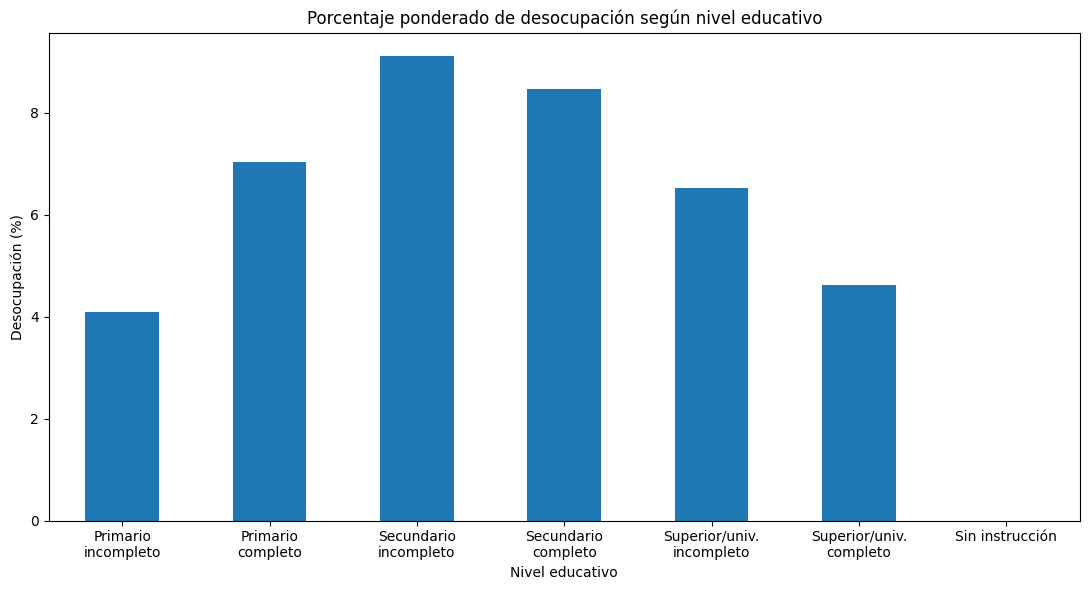

In [ ]:
import matplotlib.pyplot as plt

nombres_nivel = {
    1: "Primario\nincompleto",
    2: "Primario\ncompleto",
    3: "Secundario\nincompleto",
    4: "Secundario\ncompleto",
    5: "Superior/univ.\nincompleto",
    6: "Superior/univ.\ncompleto",
    7: "Sin instrucción",
    9: "Ns/Nr"
}

porcentaje_desocupacion = tabla_porcentajes[2].copy()

porcentaje_desocupacion.index = (
    porcentaje_desocupacion.index.map(nombres_nivel)
)

ax = porcentaje_desocupacion.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Porcentaje ponderado de desocupación según nivel educativo")
ax.set_xlabel("Nivel educativo")
ax.set_ylabel("Desocupación (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.show()

El gráfico muestra que la desocupación alcanza su mayor proporción entre las personas con secundario incompleto (9,11 %), seguida por quienes completaron el secundario (8,46 %). En los niveles de educación superior completa y primaria incompleta se observan porcentajes menores, lo que evidencia diferencias en la desocupación según el nivel educativo alcanzado.

### 3.2 Educación e Informalidad Laboral (Pregunta 2)

En esta sección analizaremos la proporción de empleo informal según el nivel educativo para la población ocupada (`ESTADO == 1`).
Recordemos que según la codificación de la variable `EMPLEO`:
* `1.0` = Formal
* `2.0` = Informal

In [ ]:
poblacion_ocupada = data_set_limpio[data_set_limpio["ESTADO"] == 1].copy()


# Calcular porcentajes ponderados de formalidad e informalidad

tabla_informalidad = porcentaje_ponderado(
    poblacion_ocupada,
    filas="NIVEL_ED",
    columnas="EMPLEO"
)

tabla_informalidad.round(2)


EMPLEO,1.0,2.0
NIVEL_ED,,
1,22.53,77.47
2,26.69,73.31
3,20.47,79.53
4,42.85,57.15
5,48.69,51.31
6,80.04,19.96
7,60.48,39.52


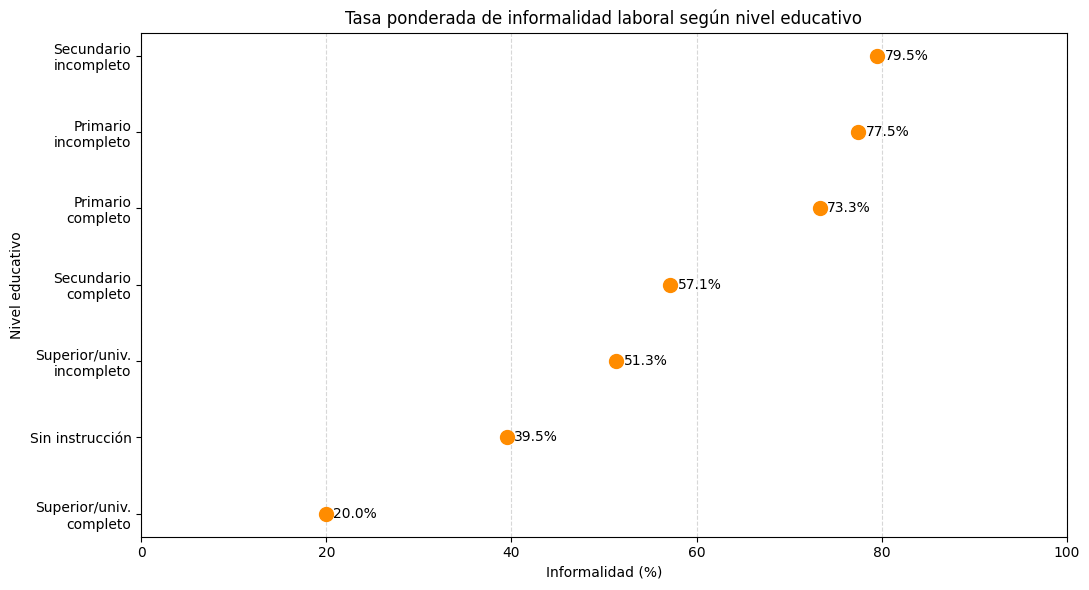

In [ ]:
porcentaje_informalidad = tabla_informalidad[2.0].copy()

porcentaje_informalidad.index = (
    porcentaje_informalidad.index.map(nombres_nivel)
)

porcentaje_informalidad = porcentaje_informalidad.sort_values(
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.scatter(
    porcentaje_informalidad.values,
    porcentaje_informalidad.index,
    color="darkorange",
    s=100,
    zorder=3
)

for x, y in zip(
    porcentaje_informalidad.values,
    porcentaje_informalidad.index
):
    plt.text(x + 0.8, y, f"{x:.1f}%", va="center")

plt.title(
    "Tasa ponderada de informalidad laboral según nivel educativo"
)
plt.xlabel("Informalidad (%)")
plt.ylabel("Nivel educativo")
plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

Se observa una elevada proporción de informalidad laboral en los niveles educativos más bajos, alcanzando su máximo entre las personas con secundario incompleto (79,53 %). En contraste, entre quienes completaron el nivel superior/universitario, la informalidad desciende al 19,96 %, mostrando una asociación entre mayor nivel educativo y menor incidencia del empleo informal.

### 3.3 Educación e Ingresos (Pregunta 3)

En esta sección analizaremos la relación entre el nivel educativo y los ingresos de las personas. Utilizaremos:
* `P21`: Ingreso de la ocupación principal (solo para ocupados con ingresos válidos mayores a cero).
* `P47T`: Ingreso total individual (para personas con ingresos totales válidos mayores a cero).

In [ ]:

# Filtrar ingresos válidos y positivos

ingresos_laborales = data_set_limpio[
    (data_set_limpio["ESTADO"] == 1) &
    (data_set_limpio["P21"] > 0)
].copy()

ingresos_totales = data_set_limpio[
    data_set_limpio["P47T"] > 0
].copy()


# Función para calcular promedios ponderados por grupo

def promedio_ponderado_por_grupo(df, variable):
    numerador = (
        (df[variable] * df["PONDERA"])
        .groupby(df["NIVEL_ED"])
        .sum()
    )

    denominador = (
        df.groupby("NIVEL_ED")["PONDERA"]
        .sum()
    )

    return numerador / denominador


# Calcular promedios ponderados

promedio_p21 = promedio_ponderado_por_grupo(
    ingresos_laborales, "P21"
)

promedio_p47t = promedio_ponderado_por_grupo(
    ingresos_totales, "P47T"
)


# Crear tabla de resultados

tabla_ingresos = pd.DataFrame({
    "Ingreso Ocupación Principal (P21)": promedio_p21,
    "Ingreso Total Individual (P47T)": promedio_p47t
})

tabla_ingresos.index = (
    tabla_ingresos.index.map(nombres_nivel)
)

tabla_ingresos.round(2)



,Ingreso Ocupación Principal (P21),Ingreso Total Individual (P47T)
NIVEL_ED,,
Primario\nincompleto,441583.77,459354.83
Primario\ncompleto,587255.20,577578.47
Secundario\nincompleto,652860.87,648996.31
Secundario\ncompleto,681136.86,735374.32
Superior/univ.\nincompleto,676872.82,701264.34
Superior/univ.\ncompleto,1075197.28,1282665.29
Sin instrucción,919929.76,639109.12


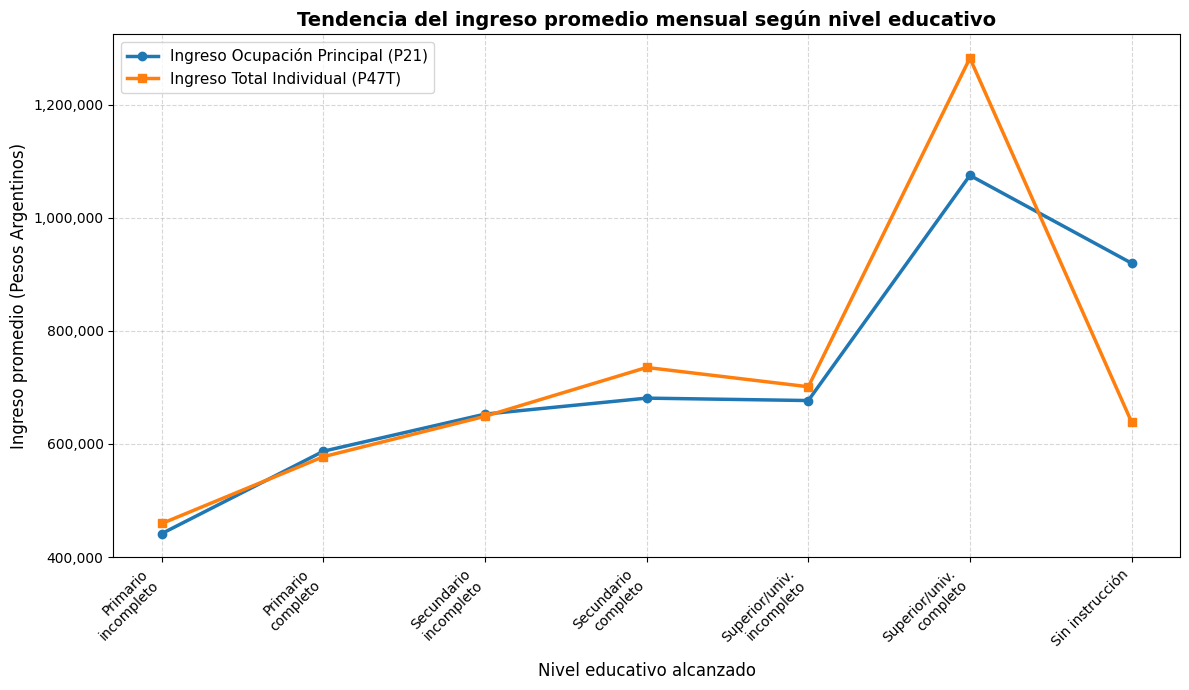

In [ ]:
# 4. Gráfico de líneas para visualizar la tendencia de ingresos promedio según nivel educativo
plt.figure(figsize=(12, 7))

plt.plot(tabla_ingresos.index, tabla_ingresos["Ingreso Ocupación Principal (P21)"],
         marker='o', linewidth=2.5, label="Ingreso Ocupación Principal (P21)", color="#1f77b4")
plt.plot(tabla_ingresos.index, tabla_ingresos["Ingreso Total Individual (P47T)"],
         marker='s', linewidth=2.5, label="Ingreso Total Individual (P47T)", color="#ff7f0e")

plt.title("Tendencia del ingreso promedio mensual según nivel educativo", fontsize=14, fontweight='bold')
plt.xlabel("Nivel educativo alcanzado", fontsize=12)
plt.ylabel("Ingreso promedio (Pesos Argentinos)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

import matplotlib.ticker as ticker
plt.gca().get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.tight_layout()

plt.show()


El análisis muestra una tendencia general de mayores ingresos promedio en los niveles educativos más altos. Las personas con educación superior/universitaria completa registran los mayores valores, tanto en el ingreso de la ocupación principal ($ 1.075.197,28) como en el ingreso total individual ( $$1.282.665,29). No obstante, la tendencia no es estrictamente creciente en todos los niveles educativos.

# 4. Resumen de hallazgos principales

El análisis de los microdatos de la EPH correspondientes al primer trimestre de 2026 permitió identificar diferencias en la situación laboral y económica de la población del NEA según el nivel educativo alcanzado. Los resultados presentados corresponden a estimaciones ponderadas mediante el factor de expansión `PONDERA`.

**Educación y desempleo:** la proporción general de desocupación dentro de la población económicamente activa fue del 7,19 %. Al analizarla según nivel educativo, se observó una mayor incidencia entre las personas con secundario incompleto (9,11 %) y secundario completo (8,46 %). Los porcentajes más bajos se registraron entre quienes tienen primario incompleto (4,10 %) y educación superior completa (4,61 %).

**Educación e informalidad laboral:** se identificó una mayor proporción de empleo informal entre las personas con niveles educativos más bajos. El porcentaje más elevado correspondió a quienes tienen secundario incompleto (79,53 %), mientras que entre las personas con educación superior completa descendió al 19,96 %. Estos resultados muestran una asociación entre el nivel educativo y la condición de formalidad laboral.

**Educación e ingresos:** se observó una tendencia general de mayores ingresos promedio en los niveles educativos más altos. Las personas con educación superior completa registraron los mayores promedios ponderados, alcanzando $ 1.075.197,28 en ingresos de la ocupación principal y $$1.282.665,29 en ingresos totales individuales.

En conjunto, los resultados evidencian diferencias en las condiciones laborales y económicas según el nivel educativo alcanzado. No obstante, estas asociaciones no permiten establecer relaciones causales, ya que también pueden intervenir otros factores, como la edad, la experiencia laboral, la actividad económica y las características del empleo.